# Monte Carlo normal vs antitéticas sobre acciones reales

**Activos:** AAPL, MSFT, NVDA, META, AMZN

**Procedimiento:**
1. Descargar precios de cierre de todo 2025.
2. Estimar $\mu$ y $\sigma$ anualizados con los rendimientos logarítmicos de 2025.
3. Simular del 1-ene-2026 al 30-jun-2026 con Monte Carlo normal ($M = 50$).
4. Simular el mismo periodo con antitéticas: 50 valores de $Z$ y sus 50 espejos $-Z$, 100 rutas en total.
5. Graficar rutas e histograma del precio final de ambas simulaciones.
6. Descargar los precios reales del primer semestre de 2026 y compararlos.

Se simula con $\mu$ (medida real) y no con $r$, porque el objetivo es proyectar el precio, no valuar un derivado.

### Librerías

In [37]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

tickers = ["AAPL", "MSFT", "NVDA", "META", "AMZN"]

## 1. Datos históricos de 2025

### Descarga de precios de cierre

In [38]:
data_2025 = yf.download(tickers, start = "2025-01-01", end = "2026-01-01", auto_adjust = True, progress = False)

precios = data_2025["Close"]
print(f"Observaciones: {len(precios)}")
precios.tail()

Observaciones: 250


Ticker,AAPL,AMZN,META,MSFT,NVDA
Date,,,,,
2025-12-24,273.066742,232.380005,665.835876,484.943390,188.169678
2025-12-26,272.657806,232.520004,661.586853,484.635376,190.085190
2025-12-29,273.016876,232.070007,656.998657,484.029236,187.780594
2025-12-30,272.338684,232.529999,664.239990,484.406860,187.102173
2025-12-31,271.122009,230.820007,658.395020,480.571136,186.064621


## 2. Estimación de μ y σ

### Parámetros anualizados de cada activo

In [39]:
log_ret = np.log(precios / precios.shift(1)).dropna()

sigma = log_ret.std() * np.sqrt(252)  # Volatilidad anuaizada
mu = log_ret.mean() * 252 + 0.5 * sigma**2 # Rendimiento esperado anualizado
S0 = precios.iloc[-1]  # ultimo cierre de 2025

parametros = pd.DataFrame({"mu": mu, "sigma": sigma, "S0": S0})
parametros.round(4)


,mu,sigma,S0
Ticker,,,
AAPL,0.1663,0.3216,271.1220
AMZN,0.1065,0.3433,230.8200
META,0.1725,0.3779,658.3950
MSFT,0.1826,0.2407,480.5711
NVDA,0.4270,0.4984,186.0646


## 3 y 4. Simulación del primer semestre de 2026

El horizonte son los días hábiles del NYSE entre el 1 de enero y el 30 de junio de 2026, descontando los feriados del mercado.

### Horizonte de simulación

In [40]:
feriados = ["2026-01-01", "2026-01-19", "2026-02-16",
            "2026-04-03", "2026-05-25", "2026-06-19"]

n  = np.busday_count("2026-01-01", "2026-07-01", holidays=feriados)
dt = 1 / 252
M  = 50

print(f"Días hábiles a simular: {n}")

Días hábiles a simular: 123


### Función de simulación (normal y antitética)

En la versión antitética se generan $M$ filas de $Z$ y se completan con sus espejos $-Z$, así que la simulación antitética tiene $2M$ rutas.

In [41]:
def simular(S0, mu, sigma, n, M, antiteticas=False):
    if antiteticas:
        Z_mitad = np.random.normal(0, 1, (M // 2, n))
        Z = np.vstack([Z_mitad, -Z_mitad])
    else:
        Z = np.random.normal(0, 1, (M, n))

    S = np.zeros((Z.shape[0], n + 1))
    S[:, 0] = S0
    for t in range(1, n + 1):
        S[:, t] = S[:, t-1] * np.exp((mu - 0.5*sigma**2)*dt + sigma*np.sqrt(dt)*Z[:, t-1])
    return S

### Monte Carlo normal

In [42]:
np.random.seed(42)

rutas_normal = {}
for tk in tickers:
    rutas_normal[tk] = simular(S0[tk], mu[tk], sigma[tk], n, M)


### Monte Carlo con antitéticas

In [43]:
np.random.seed(42)

rutas_anti = {}
for tk in tickers:
    rutas_anti[tk] = simular(S0[tk], mu[tk], sigma[tk], n, M, antiteticas=True)

## 5. Rutas e histograma del precio final

### Función de gráficas

In [44]:
def graficar(rutas, titulo, color):
    fig, axes = plt.subplots(len(tickers), 2, figsize=(15, 4*len(tickers)),
                             gridspec_kw={"width_ratios": [2.5, 1]})

    for i, tk in enumerate(tickers):
        S = rutas[tk]

        axes[i, 0].plot(S.T, color=color, alpha=0.25, lw=0.8)
        axes[i, 0].plot(S.mean(axis=0), color="black", lw=2, label="Promedio")
        axes[i, 0].set_title(f"{tk}: {titulo}")
        axes[i, 0].set_ylabel("Precio")
        axes[i, 0].legend(); axes[i, 0].grid(alpha=0.3)

        axes[i, 1].hist(S[:, -1], bins=15, orientation="horizontal",
                        color=color, edgecolor="black", alpha=0.8)
        axes[i, 1].axhline(S[:, -1].mean(), color="black", lw=2)
        axes[i, 1].set_ylim(axes[i, 0].get_ylim())
        axes[i, 1].set_title("Precio final")
        axes[i, 1].grid(alpha=0.3)

    axes[-1, 0].set_xlabel("Día hábil")
    axes[-1, 1].set_xlabel("Frecuencia")
    plt.tight_layout()
    plt.show()

### Gráficas: Monte Carlo normal

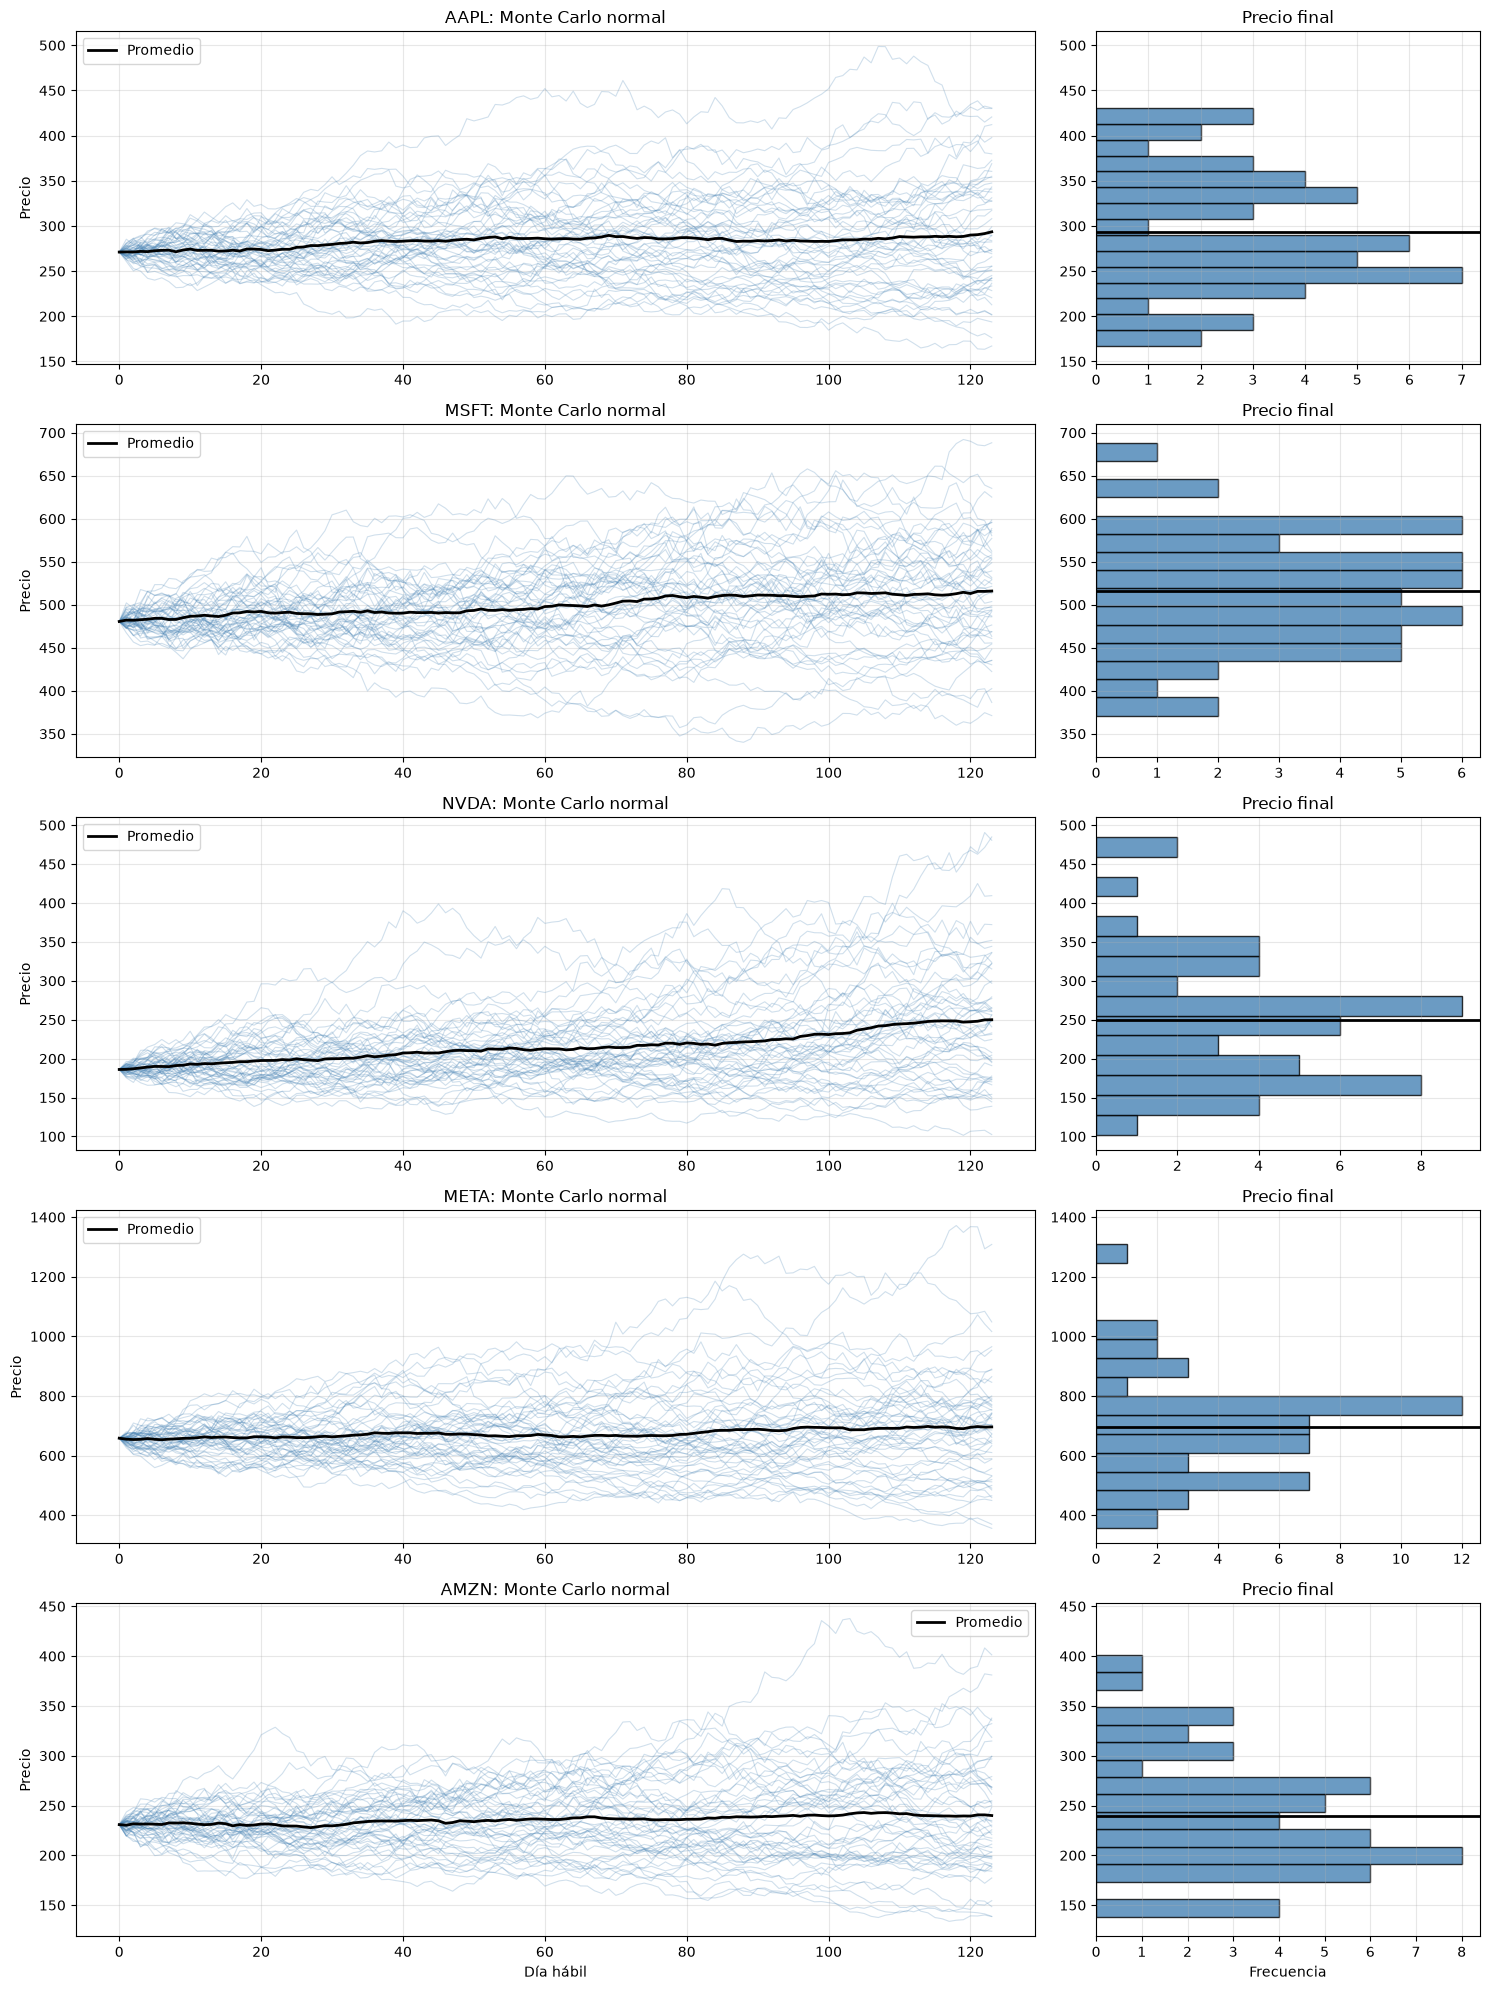

In [45]:
graficar(rutas_normal, "Monte Carlo normal", "steelblue")

### Gráficas: Monte Carlo con antitéticas

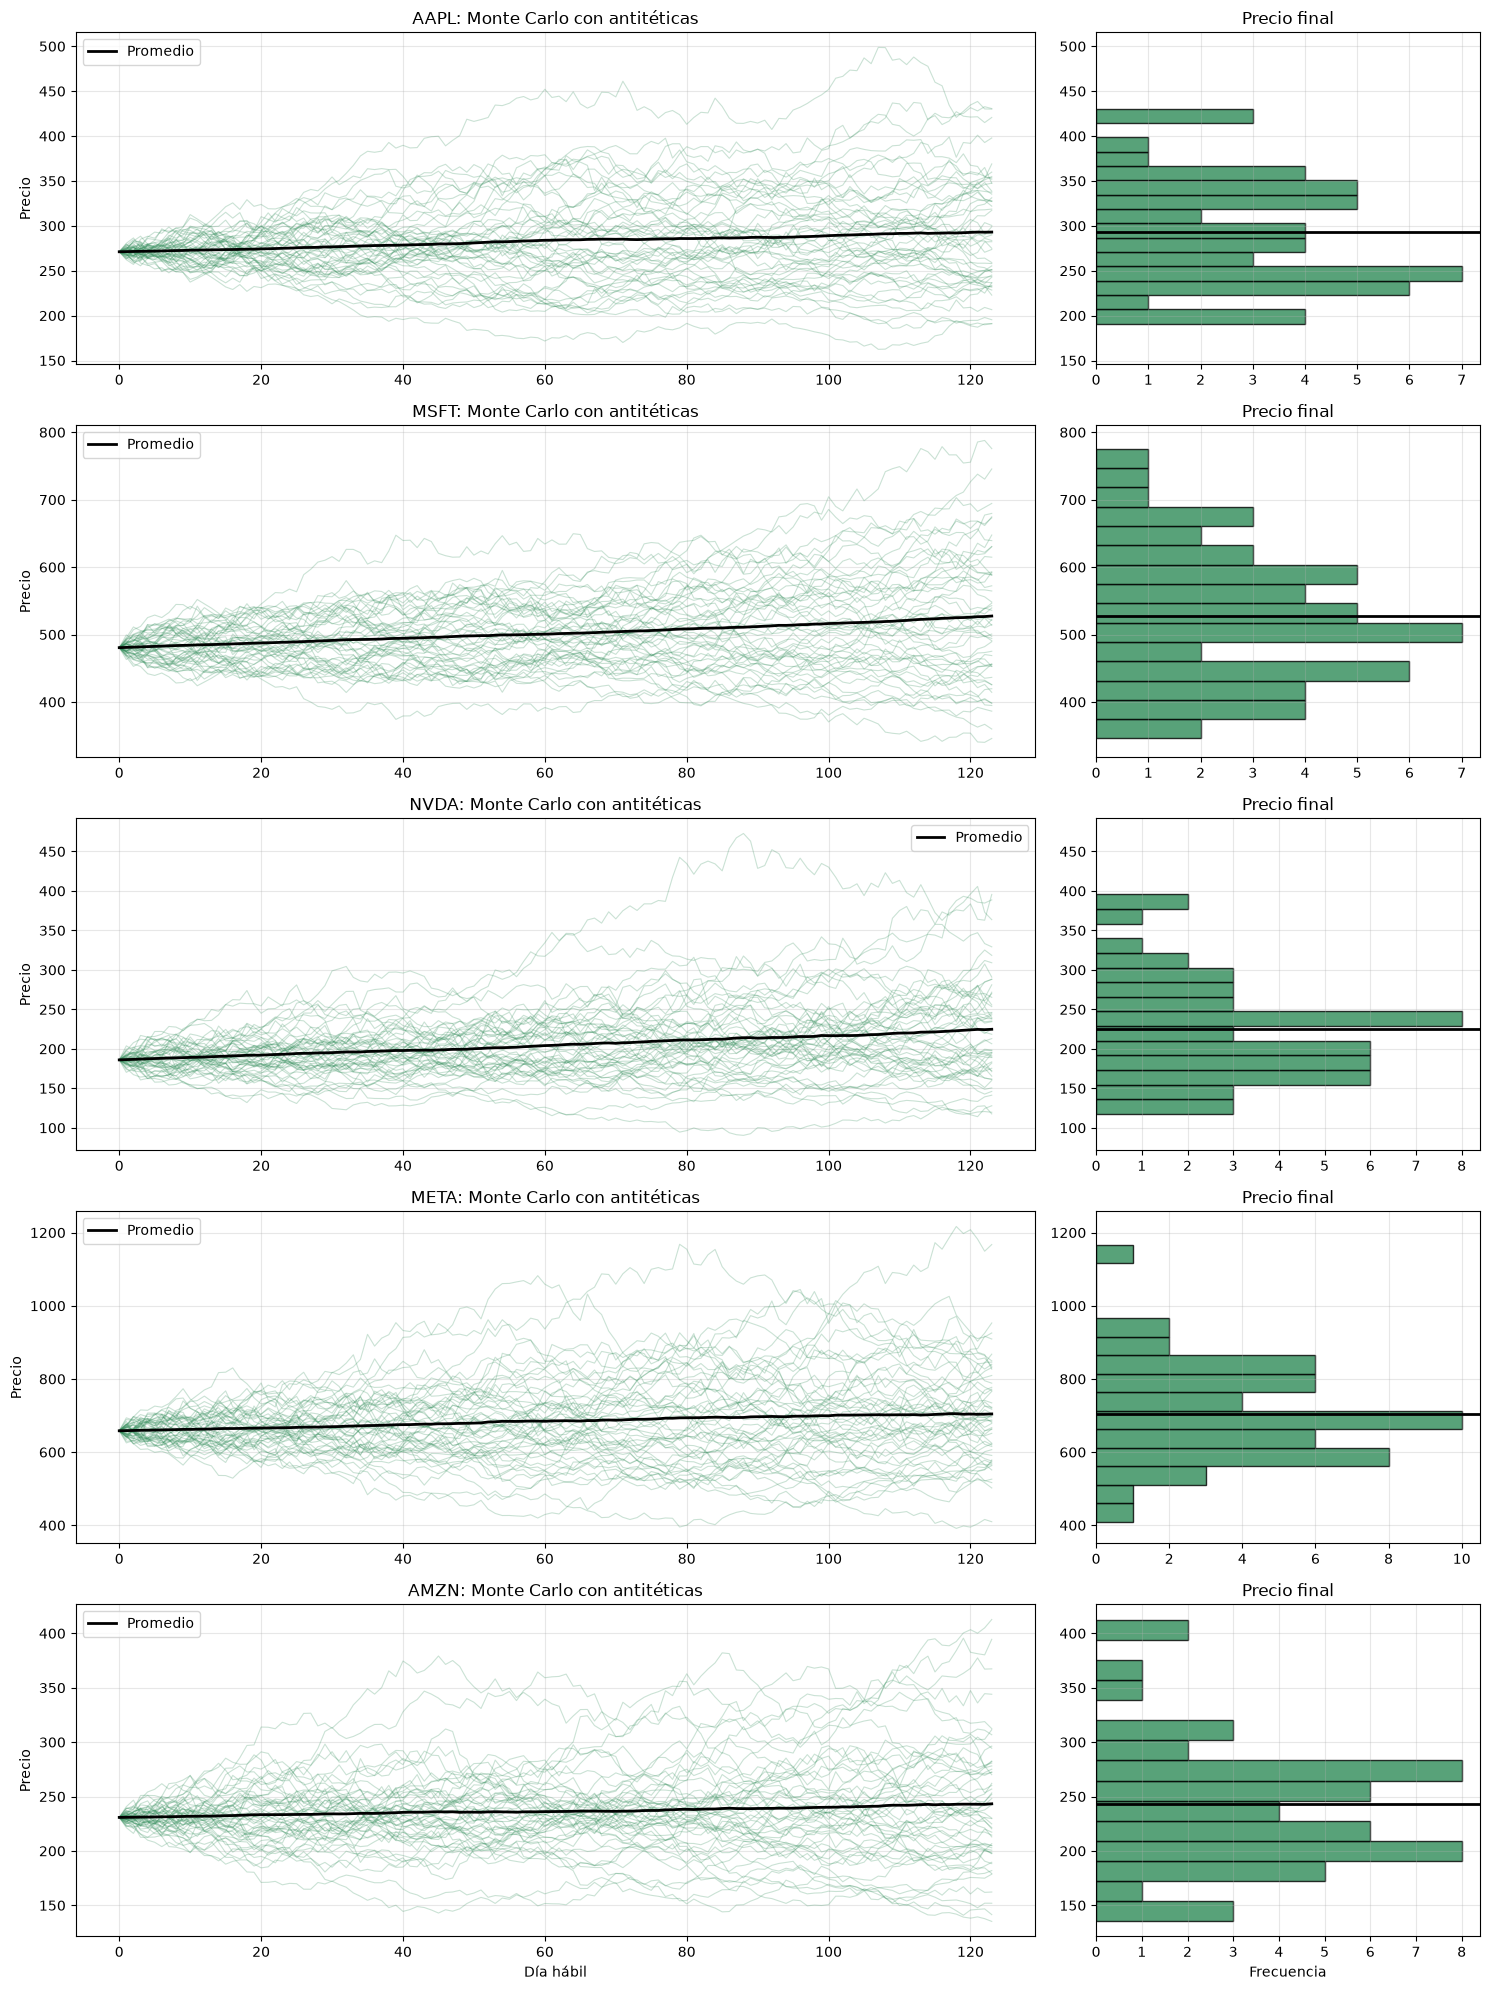

In [46]:
graficar(rutas_anti, "Monte Carlo con antitéticas", "seagreen")

## 6. Datos reales del primer semestre de 2026

### Descarga de precios reales

In [47]:
data_2026 = yf.download(tickers, start="2026-01-01", end="2026-07-01",
                        auto_adjust=True, progress=False)

reales = data_2026["Close"]
print(f"Días hábiles reales: {len(reales)}")
reales.head()

Días hábiles reales: 123


Ticker,AAPL,AMZN,META,MSFT,NVDA
Date,,,,,
2026-01-02,270.274353,226.500000,648.739868,469.958496,188.409134
2026-01-05,266.534546,233.059998,657.098328,469.869080,187.680817
2026-01-06,261.647766,240.929993,658.923645,475.493408,186.802887
2026-01-07,259.623322,241.559998,647.024292,480.422119,188.668518
2026-01-08,258.336853,246.289993,644.401062,475.095886,184.608017


### Rutas e histograma de los precios reales

La ruta real arranca en el último cierre de 2025 para que se alinee con las simulaciones. El histograma muestra la distribución de los precios diarios observados en el semestre.

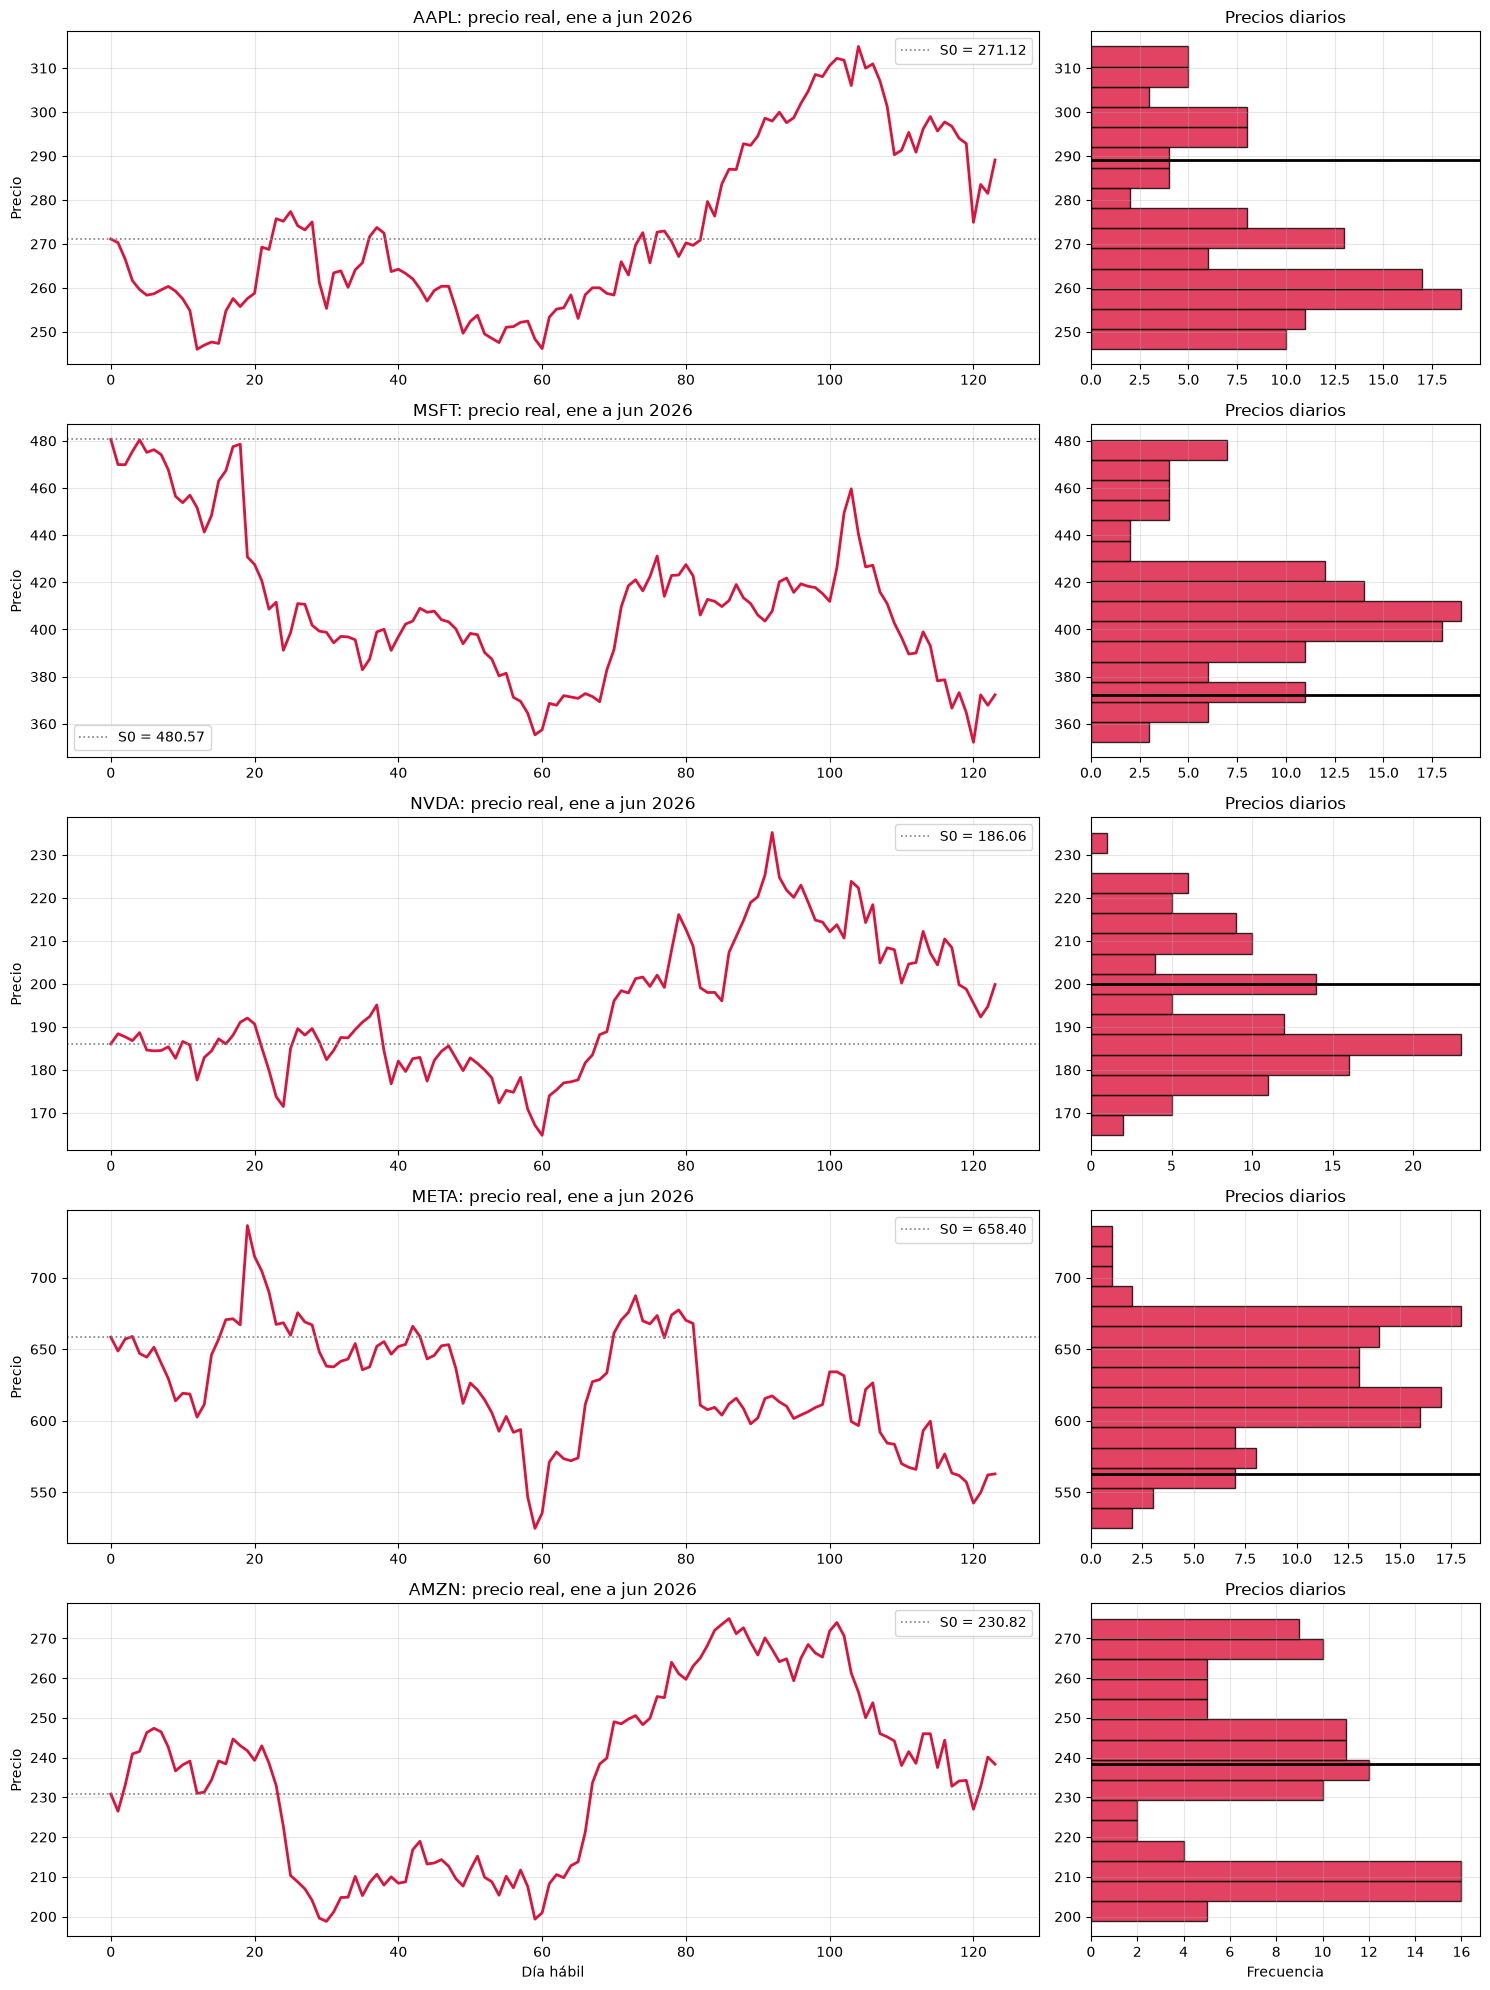

In [48]:
fig, axes = plt.subplots(len(tickers), 2, figsize=(15, 4*len(tickers)),
                         gridspec_kw={"width_ratios": [2.5, 1]})

for i, tk in enumerate(tickers):
    ruta_real = np.concatenate([[S0[tk]], reales[tk].values])

    axes[i, 0].plot(ruta_real, color="crimson", lw=2)
    axes[i, 0].axhline(S0[tk], color="gray", ls=":", lw=1.2, label=f"S0 = {S0[tk]:.2f}")
    axes[i, 0].set_title(f"{tk}: precio real, ene a jun 2026")
    axes[i, 0].set_ylabel("Precio")
    axes[i, 0].legend(); axes[i, 0].grid(alpha=0.3)

    axes[i, 1].hist(reales[tk], bins=15, orientation="horizontal",
                    color="crimson", edgecolor="black", alpha=0.8)
    axes[i, 1].axhline(reales[tk].iloc[-1], color="black", lw=2)
    axes[i, 1].set_ylim(axes[i, 0].get_ylim())
    axes[i, 1].set_title("Precios diarios")
    axes[i, 1].grid(alpha=0.3)

axes[-1, 0].set_xlabel("Día hábil")
axes[-1, 1].set_xlabel("Frecuencia")
plt.tight_layout()
plt.show()

### Comparación: simulaciones contra lo que realmente pasó

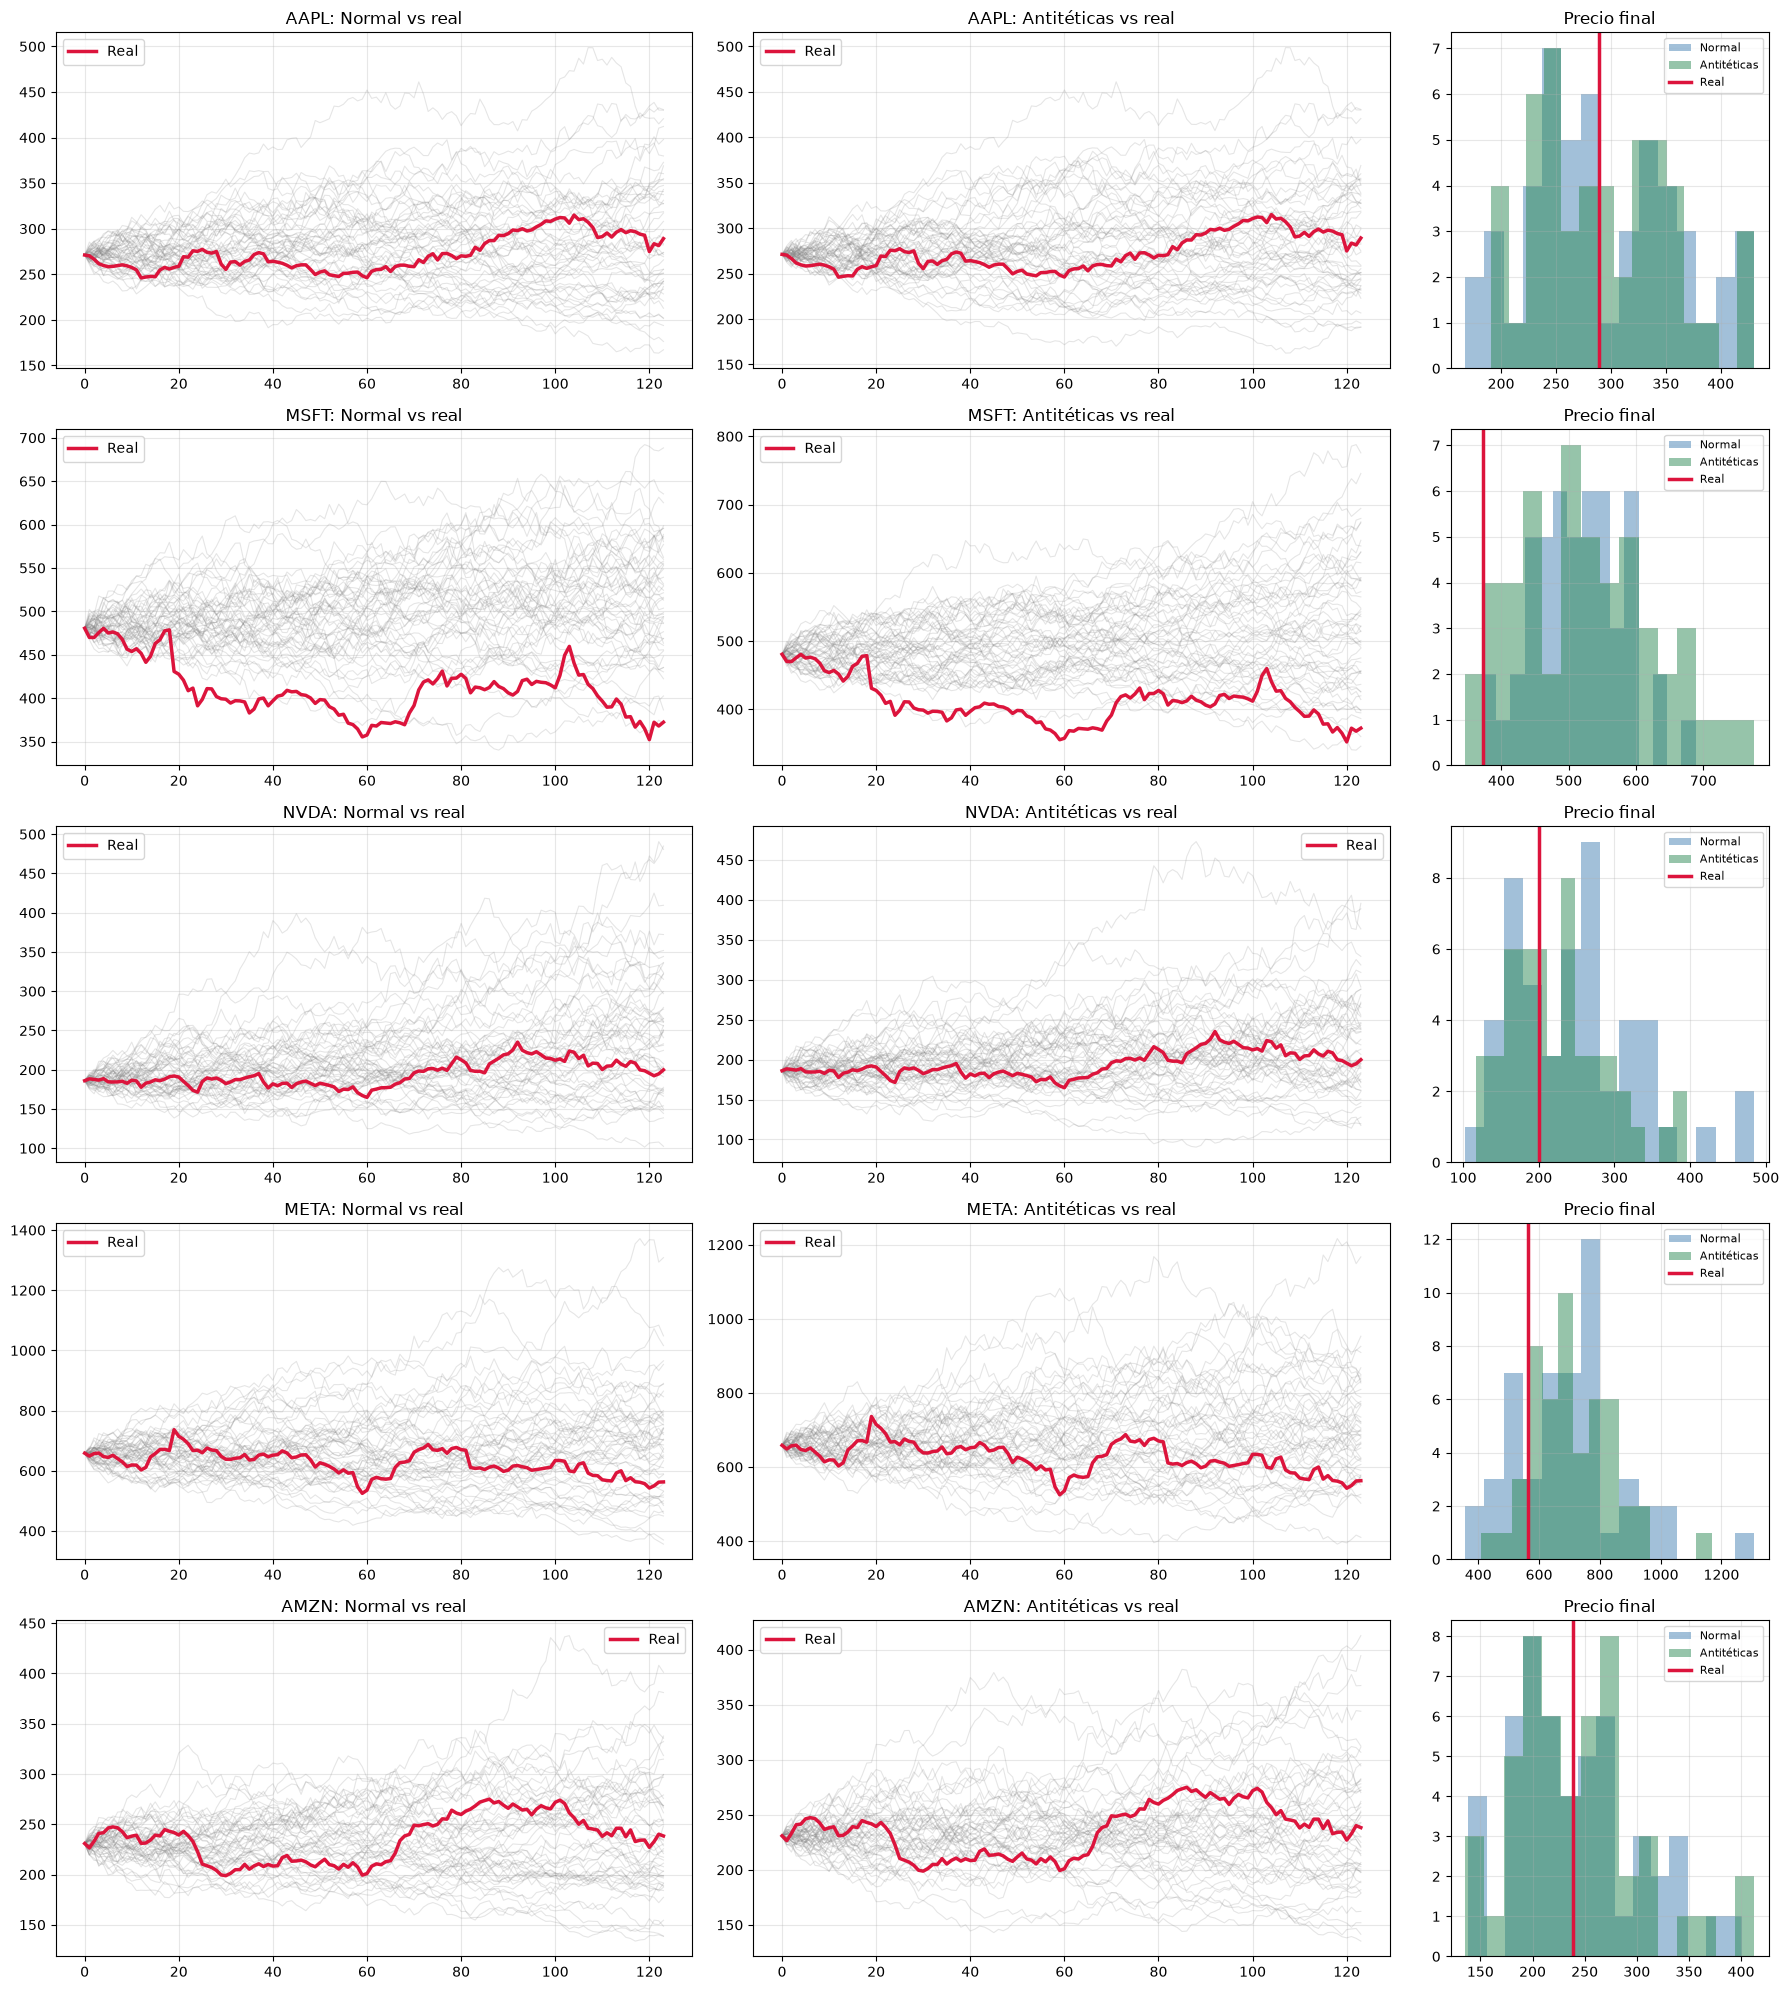

In [49]:
fig, axes = plt.subplots(len(tickers), 3, figsize=(18, 4*len(tickers)),
                         gridspec_kw={"width_ratios": [2, 2, 1]})

for i, tk in enumerate(tickers):
    ruta_real = np.concatenate([[S0[tk]], reales[tk].values])

    for j, (rutas, nombre) in enumerate([(rutas_normal, "Normal"), (rutas_anti, "Antitéticas")]):
        axes[i, j].plot(rutas[tk].T, color="gray", alpha=0.2, lw=0.8)
        axes[i, j].plot(ruta_real, color="crimson", lw=2.5, label="Real")
        axes[i, j].set_title(f"{tk}: {nombre} vs real")
        axes[i, j].legend(); axes[i, j].grid(alpha=0.3)

    axes[i, 2].hist(rutas_normal[tk][:, -1], bins=15, alpha=0.5, color="steelblue", label="Normal")
    axes[i, 2].hist(rutas_anti[tk][:, -1],   bins=15, alpha=0.5, color="seagreen",  label="Antitéticas")
    axes[i, 2].axvline(reales[tk].iloc[-1], color="crimson", lw=2.5, label="Real")
    axes[i, 2].set_title("Precio final")
    axes[i, 2].legend(fontsize=8); axes[i, 2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Tabla resumen

El percentil indica qué porcentaje de las simulaciones terminó por debajo del precio real. Un valor cercano a 50 significa que el precio real cayó en el centro de lo simulado; cerca de 0 o 100, que cayó en las colas.

In [50]:
resumen = []
for tk in tickers:
    real_ST = reales[tk].iloc[-1]
    resumen.append({
        "Activo": tk,
        "S0": S0[tk],
        "Precio real 30-jun": real_ST,
        "Media MC normal": rutas_normal[tk][:, -1].mean(),
        "Media antitéticas": rutas_anti[tk][:, -1].mean(),
        "Desv. MC normal": rutas_normal[tk][:, -1].std(ddof=1),
        "Desv. antitéticas": rutas_anti[tk][:, -1].std(ddof=1),
        "Percentil real (normal)": (rutas_normal[tk][:, -1] < real_ST).mean() * 100,
        "Percentil real (antitéticas)": (rutas_anti[tk][:, -1] < real_ST).mean() * 100,
    })

pd.DataFrame(resumen).round(2)

,Activo,S0,Precio real 30-jun,Media MC normal,Media antitéticas,Desv. MC normal,Desv. antitéticas,Percentil real (normal),Percentil real (antitéticas)
0,AAPL,271.12,289.11,293.53,293.06,67.99,62.05,54.0,50.0
1,MSFT,480.57,372.32,515.96,527.47,66.76,101.76,2.0,4.0
2,NVDA,186.06,199.87,249.99,224.79,84.06,65.99,34.0,46.0
3,META,658.40,562.85,696.24,704.37,182.44,137.31,26.0,10.0
4,AMZN,230.82,238.34,239.95,243.31,59.27,60.45,56.0,50.0


### Precisión del precio esperado: normal vs antitéticas

El valor esperado teórico del precio al 30 de junio es $E[S_T] = S_0 e^{\mu T}$, con $T = n/252$.

El error estándar del promedio se calcula distinto en cada método: en el normal con las 50 rutas independientes, y en el antitético con los 25 promedios de cada par $(Z, -Z)$, porque las dos rutas de un par no son independientes.

In [51]:
T = n / 252
precision = []

for tk in tickers:
    E_teorico = S0[tk] * np.exp(mu[tk] * T)

    final_normal = rutas_normal[tk][:, -1]
    final_anti   = rutas_anti[tk][:, -1]

    mitad = len(final_anti) // 2
    pares = (final_anti[:mitad] + final_anti[mitad:]) / 2

    precision.append({
        "Activo": tk,
        "E[S_T] teórico": E_teorico,
        "Media normal": final_normal.mean(),
        "Media antitéticas": final_anti.mean(),
        "Error normal": abs(final_normal.mean() - E_teorico),
        "Error antitéticas": abs(final_anti.mean() - E_teorico),
        "SE normal": final_normal.std(ddof=1) / np.sqrt(len(final_normal)),
        "SE antitéticas": pares.std(ddof=1) / np.sqrt(mitad),
    })

pd.DataFrame(precision).round(2)

,Activo,E[S_T] teórico,Media normal,Media antitéticas,Error normal,Error antitéticas,SE normal,SE antitéticas
0,AAPL,294.05,293.53,293.06,0.53,0.99,9.62,1.43
1,MSFT,525.36,515.96,527.47,9.41,2.10,9.44,2.23
2,NVDA,229.18,249.99,224.79,20.80,4.39,11.89,2.34
3,META,716.23,696.24,704.37,19.99,11.86,25.80,4.02
4,AMZN,243.14,239.95,243.31,3.18,0.17,8.38,2.00


---

# Conclusiones

## 1. Las antitéticas mejoran la estimación del precio esperado

Los dos métodos usan 50 rutas, así que la comparación es directa.

| Activo | E[S_T] teórico | Media normal | Media antitéticas | Error normal | Error antitéticas |
|---|---|---|---|---|---|
| AAPL | 294.05 | 293.52 | 293.05 | 0.53 | 0.99 |
| MSFT | 525.37 | 515.96 | 527.47 | 9.41 | 2.10 |
| NVDA | 229.18 | 249.98 | 224.79 | **20.80** | **4.39** |
| META | 716.23 | 696.25 | 704.37 | 19.98 | 11.86 |
| AMZN | 243.14 | 239.95 | 243.31 | 3.18 | 0.17 |

En cuatro de los cinco activos el promedio antitético quedó más cerca del valor teórico. El caso más claro es NVDA: con Monte Carlo normal el promedio se fue a 249.98, casi 21 dólares arriba de lo esperado, porque en la muestra tocaron varias rutas muy alcistas. Con antitéticas, cada ruta alcista trae su espejo bajista y el error baja a 4.39. En AAPL el método normal quedó ligeramente mejor, pero por suerte de la muestra: con 50 rutas cualquier corrida individual puede atinarle.

El error estándar del promedio es la medida que no depende de la suerte, y ahí la diferencia es clara: con el método normal está entre 8 y 26 dólares, y con antitéticas entre 1.4 y 4. Con el mismo número de rutas, el estimador antitético es entre 4 y 7 veces más preciso.

Funcionan tan bien aquí porque el precio final es casi una función lineal de los choques: cuando Z sube, S_T sube, y cuando Z baja, S_T baja. No hay un "codo" como el max(·, 0) de las opciones que corte un lado del par, así que la compensación entre Z y −Z es casi completa.

## 2. Lo que las antitéticas no cambian: la dispersión del precio

La desviación estándar de los precios finales no tiene por qué bajar con antitéticas. Esa dispersión refleja la volatilidad del activo, no un error de simulación: las antitéticas no hacen que la acción sea menos riesgosa, solo hacen que el promedio estimado sea más confiable. Las diferencias que se ven en la tabla resumen (por ejemplo, MSFT 66.76 contra 101.75) son ruido de muestreo, porque en la versión antitética solo hay 25 valores independientes. Por eso la métrica correcta para compararlas es el error estándar del promedio, no la desviación de las rutas.

## 3. Simulación contra realidad

| Activo | Rendimiento real | Percentil del precio real (antitéticas) |
|---|---|---|
| AAPL | +6.6% | 50% |
| AMZN | +3.3% | 50% |
| NVDA | +7.4% | 46% |
| META | −14.5% | 10% |
| MSFT | **−22.5%** | **4%** |

En AAPL, AMZN y NVDA el precio real cayó prácticamente en el centro de lo simulado. META quedó en la parte baja, con solo 5 de las 50 rutas por debajo del precio real.

MSFT es el caso interesante. El modelo esperaba una subida cercana a 9% y la acción cayó 22.5%. Con la volatilidad más baja de los cinco activos (24%), una caída así equivale a un movimiento de casi 2 desviaciones estándar, al que el modelo le asignaba alrededor de 2.5% de probabilidad. Solo 2 de las 50 rutas terminaron por debajo del precio real.

Eso no es un error de simulación: es error de modelo. Las antitéticas reducen el ruido de la estimación, pero no pueden corregir parámetros que no describen lo que va a pasar. El μ y el σ salieron de 2025, y en 2026 el mercado se comportó distinto, sobre todo para MSFT y META.

## 4. Sobre los parámetros

Los cinco μ estimados con 2025 fueron positivos, entre 10.6% y 42.7%, pero dos de las cinco acciones bajaron en el semestre. Un año de datos no alcanza para estimar bien el rendimiento esperado: NVDA tenía un μ de 42.7% y en la realidad subió 7.4%. La volatilidad se estima mucho mejor, y el ancho del abanico de rutas resultó razonable para cuatro de los cinco activos.

## Conclusión general

Las antitéticas cumplen lo que prometen: con el mismo número de rutas, el promedio simulado es varias veces más preciso. Pero mejorar la precisión de la simulación no mejora la calidad del pronóstico. Si los parámetros no reflejan el comportamiento futuro del activo, la simulación converge con mucha precisión a un número que no corresponde a la realidad.